# Topics in AI | Assignment No. 01 (CLO-I)

## SARSA Reinforcement Learning Agent on Gymnasium Taxi-v3

**Student:** Syed M Awais Raza  
**Registration:** FA23-BAI-044  
**University:** COMSATS University Islamabad, Attock Campus



### 1. Install Gymnasium and create the project directory

The following installation runs on Google Colab (internet required). We choose `Taxi-v3` because its discrete state/action spaces make on-policy SARSA easy to inspect.

In [1]:
!pip -q install "gymnasium[toy-text]>=1.1,<2" numpy pandas matplotlib imageio pillow reportlab pygame

import os
from pathlib import Path
os.environ['SDL_VIDEODRIVER'] = 'dummy'
PROJECT = Path('/content/Syed_M_Awais_Raza_SARSA_Assignment')
PROJECT.mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT)
print('Project folder:', Path.cwd())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 19.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 55.9 MB/s eta 0:00:00
Project folder: /content/Syed_M_Awais_Raza_SARSA_Assignment


### 2. Agent methodology

On-policy SARSA uses the next **actually chosen** action under the same epsilon-greedy behavior policy:

\[Q(s_t,a_t) \leftarrow Q(s_t,a_t)+\alpha \left[r_{t+1}+\gamma Q(s_{t+1},a_{t+1})-Q(s_t,a_t)\right]\]

The code below saves a real `agent.py` file. Exploration decreases linearly from 1.00 to 0.05. The final tuned parameters are alpha **0.20**, gamma **0.99**, over **20,000** training episodes.

### 3. Save SARSA training and evaluation

SARSA training, epsilon-greedy action selection, terminal handling and reproducible policy evaluation.

In [2]:
%%writefile agent.py
"""From-scratch on-policy SARSA agent for Gymnasium Taxi (discrete state/action)."""
from dataclasses import dataclass
from typing import Optional
import numpy as np


@dataclass
class SARSACfg:
    episodes: int = 20000
    alpha: float = 0.20
    gamma: float = 0.99
    epsilon_start: float = 1.0
    epsilon_end: float = 0.05
    decay_fraction: float = 0.75
    max_steps: int = 200
    seed: int = 44


def epsilon_at(episode, cfg):
    progress = min(1.0, episode / max(1.0, cfg.episodes * cfg.decay_fraction))
    return cfg.epsilon_start + (cfg.epsilon_end - cfg.epsilon_start) * progress


def epsilon_greedy(q, state, epsilon, rng):
    """Random tie-breaking prevents the zero-initialized table favoring action 0."""
    if rng.random() < epsilon:
        return int(rng.integers(q.shape[1]))
    maxima = np.flatnonzero(q[state] == np.max(q[state]))
    return int(rng.choice(maxima))


def train_sarsa(env_factory, cfg: SARSACfg, verbose=True):
    """Learn SARSA's on-policy Q(s,a) table; time-limit truncated states bootstrap."""
    rng = np.random.default_rng(cfg.seed)
    env = env_factory()
    assert hasattr(env.observation_space, 'n') and hasattr(env.action_space, 'n'), 'Use discrete spaces'
    q = np.zeros((env.observation_space.n, env.action_space.n), dtype=np.float64)
    rewards, successes, steps_record, eps_record = [], [], [], []
    for ep in range(cfg.episodes):
        state, _ = env.reset(seed=cfg.seed + ep)
        eps = epsilon_at(ep, cfg)
        action = epsilon_greedy(q, state, eps, rng)
        reward_sum, success, steps = 0.0, False, 0
        for t in range(cfg.max_steps):
            state_next, reward, terminated, truncated, _ = env.step(action)
            # SARSA bootstraps on next *selected* action, except true terminal states.
            if terminated:
                target = reward
            else:
                next_action = epsilon_greedy(q, state_next, eps, rng)
                target = reward + cfg.gamma * q[state_next, next_action]
            q[state, action] += cfg.alpha * (target - q[state, action])
            reward_sum += reward
            steps = t + 1
            success = bool(terminated)
            if terminated or truncated:
                break
            state, action = state_next, next_action
        rewards.append(float(reward_sum))
        successes.append(int(success))
        steps_record.append(steps)
        eps_record.append(eps)
        if verbose and (ep + 1) % max(1, cfg.episodes // 5) == 0:
            sl = min(250, len(rewards))
            print(f'episode {ep+1:>6}/{cfg.episodes}: last-{sl} reward={np.mean(rewards[-sl:]):.2f}, success={np.mean(successes[-sl:])*100:.1f}%, eps={eps:.3f}')
    env.close()
    return q, {'rewards': rewards, 'successes': successes, 'steps': steps_record, 'epsilons': eps_record}


def evaluate(env_factory, q=None, episodes=100, seed=50000, max_steps=200, random_policy=False):
    rng = np.random.default_rng(seed + 711)
    env = env_factory()
    values, success, step_counts = [], [], []
    for episode in range(episodes):
        state, _ = env.reset(seed=seed + episode)
        total, ended, n = 0.0, False, 0
        for t in range(max_steps):
            if random_policy:
                action = int(rng.integers(env.action_space.n))
            else:
                row = q[state]
                action = int(np.flatnonzero(row == np.max(row))[0])
            state, reward, terminated, truncated, _ = env.step(action)
            total += float(reward)
            n = t + 1
            if terminated or truncated:
                ended = bool(terminated)
                break
        values.append(total)
        success.append(int(ended))
        step_counts.append(n)
    env.close()
    return {'mean_reward': float(np.mean(values)), 'success_rate': float(np.mean(success)),
            'mean_steps': float(np.mean(step_counts)), 'reward_std': float(np.std(values)),
            'episodes': episodes}


def successful_rollout(env_factory, q, search_seeds=500, max_steps=200):
    """Return a genuine successful greedy rollout for visual inspection."""
    env = env_factory()
    for seed in range(60000, 60000 + search_seeds):
        state, _ = env.reset(seed=seed)
        actions, rewards = [], []
        done = False
        for t in range(max_steps):
            a = int(np.argmax(q[state]))
            new_state, r, term, trunc, _ = env.step(a)
            actions.append(a)
            rewards.append(r)
            state = new_state
            if term or trunc:
                done = bool(term)
                break
        if done:
            env.close()
            return {'seed': seed, 'actions': actions, 'total_reward': sum(rewards), 'steps': len(actions), 'success': True}
    env.close()
    return None


Writing agent.py


### 4. Save visualization and PDF report tools

Generate convergence graphs, hyperparameter charts, an RGB-rendered GIF and a technical report computed from real results.

In [3]:
%%writefile utils.py
"""Training graphs, evaluated rollout GIF and a three-page technical report."""
from pathlib import Path
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import imageio.v2 as imageio
from reportlab.pdfgen import canvas
from reportlab.lib.colors import HexColor
from reportlab.lib.utils import ImageReader
from reportlab.pdfbase.pdfmetrics import stringWidth
from agent import successful_rollout

NAVY=HexColor('#18334a')
BLUE=HexColor('#26628b')
LIGHT=HexColor('#e6eff6')
DARK=HexColor('#22303c')
GRAY=HexColor('#53616d')
WIDTH, HEIGHT = 595.28, 841.89
LEFT, RIGHT = 50, 545


def rolling_mean(seq, window=250):
    a=np.asarray(seq,dtype=float)
    if len(a)==0: return a
    cum=np.cumsum(np.insert(a,0,0.))
    end=np.arange(1,len(a)+1)
    start=np.maximum(0,end-window)
    return (cum[end]-cum[start])/(end-start)


def plot_training(history, out_path):
    fig,ax=plt.subplots(3,1,figsize=(9.1,7.2),sharex=True)
    ep=np.arange(1,len(history['rewards'])+1)
    ax[0].plot(ep,rolling_mean(history['rewards']),lw=1.5,color='#28759c')
    ax[0].set_ylabel('Mean reward');ax[0].set_title('SARSA training convergence (rolling 250 episodes)')
    ax[1].plot(ep,rolling_mean(history['successes'])*100,lw=1.5,color='#25815d')
    ax[1].set_ylabel('Success (%)');ax[1].set_ylim(-3,103)
    ax[2].plot(ep,history['epsilons'],lw=1.3,color='#bb7528')
    ax[2].set_ylabel('Epsilon');ax[2].set_xlabel('Episode')
    for a in ax:a.grid(alpha=.23)
    fig.tight_layout(); fig.savefig(out_path,dpi=150,bbox_inches='tight');plt.close(fig)


def plot_comparison(baseline,trained,path):
    fig,ax=plt.subplots(1,2,figsize=(8.5,3.6))
    colors=['#a8acb7','#27749e']
    names=['Random','Trained SARSA']
    b=ax[0].bar(names,[baseline['mean_reward'],trained['mean_reward']],color=colors)
    ax[0].set_title('Mean evaluation reward');ax[0].set_ylabel('Reward')
    ax[0].axhline(0,color='black',linewidth=.8)
    c=ax[1].bar(names,[100*baseline['success_rate'],100*trained['success_rate']],color=colors)
    ax[1].set_title('Successful deliveries');ax[1].set_ylabel('Success (%)');ax[1].set_ylim(0,105)
    for a in ax:a.grid(axis='y',alpha=.2);a.set_axisbelow(True)
    fig.tight_layout();fig.savefig(path,dpi=160,bbox_inches='tight');plt.close(fig)


def plot_sensitivity(records,path):
    fig,axs=plt.subplots(1,2,figsize=(9,3.5))
    for ax,param in zip(axs,['alpha','gamma']):
        items=sorted([r for r in records if r['parameter']==param],key=lambda r:r['value'])
        ax.plot([r['value'] for r in items],[r['mean_reward'] for r in items],marker='o',color='#2972a5')
        ax.set_xlabel('Learning rate (alpha)' if param=='alpha' else 'Discount factor (gamma)')
        ax.set_ylabel('Mean reward');ax.grid(alpha=.25)
        ax.set_title(f'{param.capitalize()} sensitivity')
    fig.tight_layout();fig.savefig(path,dpi=150,bbox_inches='tight');plt.close(fig)


def render_gif(env_factory, q, path, fps=3):
    """Find a successful rollout and save frames emitted by env.render()."""
    rollout=successful_rollout(env_factory,q,search_seeds=600)
    if rollout is None:
        raise RuntimeError('No successful greedy rollout found in 600 seeds. Increase SARSA training episodes.')
    # The same reset seed and deterministic chosen actions recreate this exact sequence.
    env=env_factory(render_mode='rgb_array')
    state,_=env.reset(seed=rollout['seed'])
    frames=[env.render()]
    for action in rollout['actions']:
        state,reward,term,trunc,_=env.step(action)
        frames.append(env.render())
        if term or trunc:break
    env.close()
    # Hold the final state long enough to notice success.
    frames.extend([frames[-1]]*4)
    imageio.mimsave(path,frames,duration=1/fps,loop=0)
    return rollout


def _title(c,text,y,size=13):
    c.setFillColor(BLUE);c.setFont('Helvetica-Bold',size);c.drawString(LEFT,y,text)
    return y-19


def _text(c,text,x,y,max_w=495,font='Helvetica',size=9.5,leading=14):
    """A tiny word wrapper that returns the next baseline."""
    c.setFont(font,size);c.setFillColor(DARK)
    lines=[]
    for para in text.split('\n'):
        if not para.strip():lines.append('');continue
        words=para.split();line=''
        for word in words:
            candidate=f'{line} {word}'.strip()
            if stringWidth(candidate,font,size)>max_w and line:
                lines.append(line);line=word
            else: line=candidate
        lines.append(line)
    for line in lines:
        c.drawString(x,y,line);y-=leading
    return y


def _table(c, x, y, widths, rows, font_size=9.0, row_height=25):
    total_w=sum(widths)
    for idx,row in enumerate(rows):
        if idx==0:
            c.setFillColor(LIGHT)
            c.rect(x,y-row_height,total_w,row_height,fill=1,stroke=0)
        elif idx%2==0:
            c.setFillColor(HexColor('#f8fafc'))
            c.rect(x,y-row_height,total_w,row_height,fill=1,stroke=0)
        c.setStrokeColor(HexColor('#d3dee6'))
        c.rect(x,y-row_height,total_w,row_height,fill=0,stroke=1)
        cur=x
        for val,w in zip(row,widths):
            c.setFillColor(DARK)
            c.setFont('Helvetica-Bold' if idx==0 else 'Helvetica',font_size)
            v=str(val)
            while stringWidth(v,'Helvetica',font_size)>w-12 and len(v)>2: v=v[:-2]+'…'
            c.drawString(cur+7,y-row_height+8,v)
            cur+=w
        y-=row_height
    return y


def _page(c,page):
    c.setStrokeColor(HexColor('#cbd7df'))
    c.line(LEFT,39,RIGHT,39)
    c.setFillColor(GRAY);c.setFont('Helvetica',8.5)
    c.drawCentredString(WIDTH/2,27,f'Topics in AI | Assignment 01 | FA23-BAI-044 | Page {page} of 3')
    c.showPage()


def make_report(out_pdf, results, history, sensitivity, plot_files, rollout, meta):
    """PDF is generated from measured metrics; no values are hardcoded."""
    c=canvas.Canvas(str(out_pdf),pagesize=(WIDTH,HEIGHT),pageCompression=1)
    c.setTitle('SARSA Reinforcement Learning Technical Report - Syed M Awais Raza')
    # PAGE ONE
    c.setFillColor(NAVY);c.setFont('Helvetica-Bold',19)
    c.drawString(LEFT,795,'Syed M Awais Raza')
    c.setFont('Helvetica-Bold',11);c.drawString(LEFT,776,'FA23-BAI-044')
    c.drawString(LEFT,753,'Topics in AI | Assignment No. I (CLO-I)')
    c.setFont('Helvetica-Bold',15);c.drawString(LEFT,727,'Custom RL Agent: SARSA on Taxi-v3')
    y=695
    y=_title(c,'1. Problem Description',y)
    y=_text(c,'Taxi-v3 is a discrete 5 x 5 transportation task. A taxi must collect a waiting passenger and deliver the passenger to the indicated goal. The observation is an integer representing 500 possible states (5 rows x 5 columns x 5 passenger statuses x 4 destinations). Six actions are available: south, north, east, west, pickup, and dropoff.',LEFT,y)
    y-=8
    y=_text(c,'Rewards: -1 per ordinary step, -10 for illegal pickup/dropoff, and +20 for successful delivery. An episode ends at delivery or after 200 steps. The objective is to maximize cumulative reward by planning efficient trips.',LEFT,y)
    y-=20;y=_title(c,'2. Methodology: On-policy SARSA',y)
    y=_text(c,'Unlike Q-Learning, SARSA estimates the action value of the action actually chosen under the epsilon-greedy behavior policy. Its temporal-difference update is:',LEFT,y)
    y-=6
    c.setFillColor(NAVY);c.setFont('Courier-Bold',10)
    c.drawString(LEFT+17,y,'Q(s,a) <- Q(s,a) + alpha * [r + gamma * Q(s_next,a_next) - Q(s,a)]')
    y-=25
    y=_text(c,'The next action is selected by the same epsilon-greedy policy before updating the current state-action pair. True terminal transitions use only the immediate reward; time-limit truncated transitions may still bootstrap. Epsilon decays linearly for a balance of exploration and exploitation. Values are stored in a 500 x 6 NumPy table.',LEFT,y)
    y-=18;y=_title(c,'3. Experimental Setup',y)
    cfg=meta['config']
    settings=[['Setting','Value','Setting','Value'],['Environment','Taxi-v3','Algorithm','Tabular SARSA'],
              ['Episodes',str(cfg['episodes']),'Learning rate',str(cfg['alpha'])],
              ['Gamma',str(cfg['gamma']),'Max steps',str(cfg['max_steps'])],
              ['Initial epsilon',str(cfg['epsilon_start']),'Final epsilon',str(cfg['epsilon_end'])],
              ['Decay fraction',str(cfg['decay_fraction']),'Random seed',str(cfg['seed'])],
              ['Evaluation episodes',str(meta['eval_episodes']),'Q-table','500 x 6']]
    y=_table(c,LEFT,y,[140,105,142,108],settings,row_height=22,font_size=8.5)
    y-=16
    y=_text(c,'Execution provenance: '+meta['backend_label']+'. Evaluation uses identical starting seeds for the trained agent and random baseline. This report is regenerated when main.py runs in Colab.',LEFT,y,size=8.5,leading=13)
    _page(c,1)
    # PAGE TWO
    y=790
    y=_title(c,'4. Results: Training Convergence',y)
    plot=str(plot_files['training'])
    c.drawImage(ImageReader(plot),LEFT+18,367,width=458,height=385,preserveAspectRatio=False,mask='auto')
    y=350
    slice_n=min(250,len(history['rewards']))
    early=np.mean(history['rewards'][:slice_n]);late=np.mean(history['rewards'][-slice_n:])
    y=_text(c,f'Mean training reward: first {slice_n} episodes {early:.2f}; last {slice_n} episodes {late:.2f}. Final rolling success rate: {np.mean(history["successes"][-slice_n:])*100:.1f}%. Curves reveal how the SARSA policy changes as exploration decreases.',LEFT,y,size=9.4)
    y-=20;y=_title(c,'5. Evaluation: Random Policy vs Trained SARSA',y)
    rows=[['Policy','Mean reward','Success rate','Mean steps'],
          ['Random baseline',f'{results["random"]["mean_reward"]:.2f}',f'{results["random"]["success_rate"]*100:.1f}%',f'{results["random"]["mean_steps"]:.1f}'],
          ['Trained SARSA',f'{results["trained"]["mean_reward"]:.2f}',f'{results["trained"]["success_rate"]*100:.1f}%',f'{results["trained"]["mean_steps"]:.1f}']]
    y=_table(c,LEFT,y,[165,120,110,100],rows,row_height=27)
    y-=16
    y=_text(c,'Both policies were evaluated for '+str(meta['eval_episodes'])+' episodes with the same reset seed sequence. Greedy evaluation disables epsilon exploration; a success is a legally completed delivery. The plots and figures are from the executed experiments.',LEFT,y)
    _page(c,2)
    # PAGE THREE
    y=790;y=_title(c,'6. Hyperparameter Sensitivity',y)
    c.drawImage(ImageReader(str(plot_files['sensitivity'])),LEFT+12,566,width=470,height=198,mask='auto')
    y=550
    table_rows=[['Parameter','Value','Mean reward','Success rate']]
    for row in sensitivity:
        table_rows.append([row['parameter'],f'{row["value"]:.2f}',f'{row["mean_reward"]:.2f}',f'{row["success_rate"]*100:.1f}%'])
    y=_table(c,LEFT,y,[135,90,135,135],table_rows,font_size=8.9,row_height=23)
    y-=13
    best=max(sensitivity,key=lambda x:(x['mean_reward'],x['success_rate']))
    y=_text(c,f'Each candidate used {meta["sensitivity_episodes"]} training episodes and {meta["eval_episodes"]} common evaluation seeds. Best tested shorter-run setting: {best["parameter"]}={best["value"]:.2f}, mean reward {best["mean_reward"]:.2f}, success {best["success_rate"]*100:.1f}%. These shorter runs are not a substitute for the full experiment.',LEFT,y,size=8.6,leading=12)
    y-=17;y=_title(c,'7. Discussion and Failure Modes',y)
    y=_text(c,'Early SARSA episodes often wander and incur illegal pickup or dropoff penalties. With enough visits, the learned values can prefer legal and shorter routes. The on-policy target incorporates the next exploratory action, which can make SARSA more conservative than off-policy Q-Learning during training. Weaknesses include incomplete state coverage, slow convergence, and sensitivity to exploration decay and learning rate.',LEFT,y,size=9,leading=13)
    y-=16;y=_title(c,'8. Conclusion',y)
    statement=(f'SARSA achieved {results["trained"]["success_rate"]*100:.1f}% successful deliveries with mean reward '
               f'{results["trained"]["mean_reward"]:.2f} in {meta["eval_episodes"]} evaluation episodes. '
               f'The random policy achieved {results["random"]["success_rate"]*100:.1f}% with mean reward '
               f'{results["random"]["mean_reward"]:.2f}. ')
    if rollout:
        statement+=f'A successful demo required {rollout["steps"]} steps. '
    statement+='The Q-table, training logs and animation enable reproducibility. Re-run the notebook in Google Colab to produce official Gymnasium outputs.'
    y=_text(c,statement,LEFT,y,size=9,leading=13)
    _page(c,3)
    c.save()


Writing utils.py


### 5. Save the main experiment script

Runs training, a random baseline, sensitivity studies, graph generation, GIF generation and PDF generation.

In [12]:
%%writefile main.py
"""Run and export the full SARSA Taxi-v3 assignment.

Examples:
    python main.py                      # official Gymnasium environment
    python main.py --backend reference  # offline preview, clearly labeled
    python main.py --episodes 2000 --sensitivity-episodes 500
"""
import argparse
import json
from pathlib import Path
from dataclasses import asdict, replace
import numpy as np
import pandas as pd

from agent import SARSACfg, train_sarsa, evaluate
from utils import plot_training, plot_comparison, plot_sensitivity, render_gif, make_report

STUDENT = 'Syed M Awais Raza'
REGISTRATION = 'FA23-BAI-044'


def get_environment(backend, max_steps):
    if backend == 'reference':
        from taxi_reference import TaxiReference
        return lambda render_mode=None: TaxiReference(render_mode=render_mode)
    import gymnasium as gym
    # Gymnasium gives a 500-state Taxi-v3 with exactly six discrete actions.
    return lambda render_mode=None: gym.make('Taxi-v3', render_mode=render_mode,
                                             max_episode_steps=max_steps)


def run(episodes=20000, sensitivity_episodes=4000, eval_episodes=100,
        alpha=0.20, gamma=0.99, seed=44, backend='gymnasium', output_dir='outputs'):
    out=Path(output_dir);out.mkdir(parents=True,exist_ok=True)
    cfg=SARSACfg(episodes=episodes,alpha=alpha,gamma=gamma,seed=seed)
    factory=get_environment(backend,cfg.max_steps)
    backend_label = ('Gymnasium Taxi-v3 (official)' if backend=='gymnasium' else
                     'Locally executed Taxi-compatible reference model (NOT official Gymnasium)')
    print(f'\n{STUDENT} | {REGISTRATION}\nAlgorithm: SARSA | {backend_label}')
    q, hist=train_sarsa(factory,cfg)
    np.save(out/'sarsa_q_table.npy',q)
    pd.DataFrame({'episode':np.arange(1,episodes+1),**hist}).to_csv(out/'training_history.csv',index=False)
    random_score=evaluate(factory,episodes=eval_episodes,seed=70000,random_policy=True)
    trained_score=evaluate(factory,q=q,episodes=eval_episodes,seed=70000)
    print('Baseline:',random_score)
    print('SARSA:',trained_score)
    cases = [('alpha',x) for x in [0.10,0.20,0.45]] + [('gamma',x) for x in [0.80,0.95,0.99]]
    sensitivity=[]
    for param,value in cases:
        hc=replace(cfg, episodes=sensitivity_episodes, **{param:value})
        print(f'\nSensitivity {param}={value:.2f}:')
        hp_q,_=train_sarsa(factory,hc,verbose=False)
        score=evaluate(factory,q=hp_q,episodes=eval_episodes,seed=70000)
        sensitivity.append({'parameter':param,'value':value,
                            'mean_reward':score['mean_reward'],
                            'success_rate':score['success_rate'],
                            'mean_steps':score['mean_steps']})
        print(f' mean reward={score["mean_reward"]:.2f}, success={score["success_rate"]*100:.1f}%')
    pd.DataFrame(sensitivity).to_csv(out/'hyperparameter_sensitivity.csv',index=False)
    plot_files={'training':out/'training_convergence.png',
                'comparison':out/'evaluation_comparison.png',
                'sensitivity':out/'hyperparameter_sensitivity.png'}
    plot_training(hist,plot_files['training'])
    plot_comparison(random_score,trained_score,plot_files['comparison'])
    plot_sensitivity(sensitivity,plot_files['sensitivity'])
    rollout=None
    try:
        rollout=render_gif(factory,q,out/'trained_taxi.gif')
        print('GIF successful demonstration:',rollout)
    except Exception as e:
        print(f'WARNING: GIF not produced: {e}')
    meta={'student':STUDENT,'registration':REGISTRATION,'algorithm':'SARSA',
          'environment':'Taxi-v3','backend':backend,'backend_label':backend_label,
          'config':asdict(cfg),'eval_episodes':eval_episodes,
          'sensitivity_episodes':sensitivity_episodes}
    scores={'random':random_score,'trained':trained_score}
    report={'meta':meta,'evaluation':scores,'sensitivity':sensitivity,'rollout':rollout}
    (out/'results.json').write_text(json.dumps(report,indent=2),encoding='utf-8')
    make_report(out/'technical_report.pdf',scores,hist,sensitivity,plot_files,rollout,meta)
    print('\nSaved outputs in',out.resolve())
    return report


if __name__=='__main__':
    p=argparse.ArgumentParser()
    p.add_argument('--backend',choices=['gymnasium','reference'],default='gymnasium')
    p.add_argument('--episodes',type=int,default=20000)
    p.add_argument('--sensitivity-episodes',type=int,default=4000)
    p.add_argument('--eval-episodes',type=int,default=100)
    p.add_argument('--alpha',type=float,default=0.20)
    p.add_argument('--gamma',type=float,default=0.99)
    p.add_argument('--seed',type=int,default=44)
    p.add_argument('--output-dir',default='outputs')
    a=p.parse_args()
    run(**vars(a))


Overwriting main.py


### 6. Save offline reference model

This file is only for local testing when Gymnasium is unavailable. The Colab experiment below uses official Gymnasium.

In [13]:
%%writefile taxi_reference.py
"""Offline Taxi transition reference for local smoke tests and artifact previews.

Not a substitute for official Gymnasium evaluation. Colab main.py uses Gymnasium
by default, and the PDF clearly labels which backend produced its results.
"""
from types import SimpleNamespace
import numpy as np
from PIL import Image, ImageDraw, ImageFont

MAP = [
    '+---------+',
    '|R: | : :G|',
    '| : | : : |',
    '| : : : : |',
    '| | : | : |',
    '|Y| : |B: |',
    '+---------+',
]
LOCS = ((0,0), (0,4), (4,0), (4,3))

def encode(row, col, passenger, dest):
    i = row
    i = i*5 + col
    i = i*5 + passenger
    return i*4 + dest

def decode(s):
    dest = s % 4; s //= 4
    pass_loc = s % 5; s //= 5
    col = s % 5; s //= 5
    row = s
    return row, col, pass_loc, dest

class TaxiReference:
    metadata = {'render_modes': ['rgb_array']}
    def __init__(self, render_mode=None):
        self.observation_space = SimpleNamespace(n=500)
        self.action_space = SimpleNamespace(n=6)
        self.render_mode = render_mode
        self.s = None
        self.elapsed = 0

    def reset(self, seed=None):
        rng = np.random.default_rng(seed)
        row = int(rng.integers(5)); col = int(rng.integers(5))
        passenger = int(rng.integers(4)); dst = int(rng.integers(3))
        if dst >= passenger: dst += 1
        self.s = encode(row, col, passenger, dst)
        self.elapsed = 0
        return self.s, {}

    def step(self, action):
        row, col, pas, dst = decode(self.s)
        newpas = pas
        reward = -1
        terminated = False
        if action == 0: row = min(4, row + 1)
        elif action == 1: row = max(0, row - 1)
        elif action == 2:
            if col < 4 and MAP[1+row][2*col+2] == ':': col += 1
        elif action == 3:
            if col > 0 and MAP[1+row][2*col] == ':': col -= 1
        elif action == 4:
            if pas < 4 and (row, col) == LOCS[pas]: newpas = 4
            else: reward = -10
        elif action == 5:
            if pas == 4 and (row,col) == LOCS[dst]:
                newpas = dst; terminated = True; reward = 20
            elif pas == 4 and (row,col) in LOCS:
                newpas = LOCS.index((row,col))
            else: reward = -10
        else:
            raise ValueError(action)
        self.s = encode(row, col, newpas, dst)
        self.elapsed += 1
        return self.s, reward, terminated, (self.elapsed >= 200 and not terminated), {}

    def render(self):
        im = Image.new('RGB', (470, 490), '#f6f8fb')
        dr = ImageDraw.Draw(im)
        x0, y0, cell = 42, 55, 75
        dr.text((28, 17), 'Taxi: SARSA learned policy', fill='#112944')
        row,col,pas,dst = decode(self.s)
        for r in range(5):
            for c in range(5):
                rect=(x0+c*cell,y0+r*cell,x0+(c+1)*cell,y0+(r+1)*cell)
                dr.rectangle(rect, fill='#e8eef6', outline='#bccbd9', width=1)
                if c < 4 and MAP[1+r][2*c+2] == '|':
                    x=x0+(c+1)*cell
                    dr.line((x,y0+r*cell,x,y0+(r+1)*cell), fill='#32485e', width=7)
        names=['R','G','Y','B']
        colors=['#d44839','#379959','#dda832','#4c7fbb']
        for i,(rr,cc) in enumerate(LOCS):
            xx=x0+cc*cell+8; yy=y0+rr*cell+10
            dr.rectangle((xx, yy, xx+30, yy+30), fill=colors[i])
            dr.text((xx+8,yy+8),names[i],fill='white')
        if pas<4:
            rr,cc=LOCS[pas]
            xx=x0+cc*cell+50; yy=y0+rr*cell+15
            dr.ellipse((xx-8,yy-8,xx+8,yy+8),fill='#f28500')
        xx=x0+col*cell+30; yy=y0+row*cell+46
        dr.rounded_rectangle((xx-18,yy-14,xx+24,yy+13),radius=7,fill='#ffc524',outline='#151515',width=2)
        dr.text((xx-6,yy-6),'T',fill='#151515')
        dr.text((28, 446),f'Destination: {names[dst]}   Passenger: {"onboard" if pas==4 else names[pas]}',fill='#243850')
        return np.asarray(im)

    def close(self):
        return None


def make_reference():
    return TaxiReference()


Overwriting taxi_reference.py


### 7. Save requirements

Dependency manifest for running the project outside Colab.

In [14]:
%%writefile requirements.txt
gymnasium[toy-text]>=1.1,<2
numpy>=1.24
matplotlib>=3.7
pandas>=2.0
imageio>=2.30
pillow>=9
reportlab>=4.0
pygame>=2.5


Overwriting requirements.txt


### 8. Save repository README

GitHub documentation and submission instructions.

In [15]:
%%writefile README.md
# Topics in AI, Assignment 01: SARSA on Gymnasium Taxi-v3

**Student:** Syed M Awais Raza
**Registration number:** FA23-BAI-044
**Institute:** COMSATS University Islamabad, Attock Campus
**Assignment:** Custom Reinforcement Learning Agent using Farama Gymnasium
**Algorithm:** Tabular on-policy SARSA (implemented from scratch, not a prebuilt RL trainer)

## What is different from the earlier assignment?

This submission uses **SARSA (State-Action-Reward-State-Action)** instead of Q-Learning. SARSA updates its value estimates using the **next action actually selected by the epsilon-greedy exploration policy**, rather than the maximum possible next-state action value. The agent, mathematical update, experimental results, plots, notebook, and PDF report are independently generated.

## Run on Google Colab (recommended)

1. Go to https://colab.research.google.com/ and upload `Awais_SARSA_Taxi_Colab.ipynb`.
2. Select **Runtime > Run all** and wait for 20,000 training episodes, evaluation and six short hyperparameter trials.
3. The notebook writes the full project files, runs `main.py` with the **official Gymnasium Taxi-v3 environment**, displays the plots/GIF, and downloads a submission ZIP including the updated report and generated Q-table.
4. Push the generated contents to your own GitHub repository and submit its URL together with `outputs/technical_report.pdf`.

**No dataset upload is required.** The Taxi-v3 environment provides interaction data.

## Local terminal execution

```bash
pip install -r requirements.txt
python main.py --backend gymnasium
```

Outputs are saved under `outputs/`:
- `sarsa_q_table.npy`: learned 500 x 6 Q-table
- `training_history.csv`: episode rewards, success flags, step counts, exploration settings
- `training_convergence.png`: rolling learning curves
- `evaluation_comparison.png`: baseline vs SARSA
- `hyperparameter_sensitivity.csv` and `.png`: learning-rate and discount-factor experiments
- `trained_taxi.gif`: a successful policy rollout rendered frame-by-frame
- `results.json`: exact run settings and evaluation scores
- `technical_report.pdf`: three-page report generated from measured results

## Important: provenance of prepackaged preview outputs

The sandbox used to prepare this downloadable project did not have Gymnasium installed and could not access package downloads. The initial `outputs/` bundled in this archive therefore came from **`python main.py --backend reference`**, with a locally implemented Taxi-compatible tabular transition model. They are **real experimental measurements on that local model**, not claims of successful execution on the actual Gymnasium package. The report labels the environment accordingly.

**For the final academic submission, run the Colab notebook, which installs Gymnasium and regenerates all outputs and the PDF report from the official environment.** Replace the preview `outputs/` and use the final Colab-generated ZIP for GitHub.

`taxi_reference.py` is kept for reproducible offline tests, but the assignment's main experiment and Colab notebook use Gymnasium.

## SARSA update

`Q(s,a) <- Q(s,a) + alpha * [r + gamma * Q(s_next,a_next) - Q(s,a)]`

- `alpha`: learning rate, `gamma`: discount factor
- `a_next`: action selected using the current epsilon-greedy policy
- terminal states: no next-state bootstrapping
- truncated states: use next-state bootstrapping and then end episode

## Files

- `main.py`: full training, evaluation, hyperparameter experiments and exports
- `agent.py`: SARSA implementation from scratch
- `utils.py`: plots, GIF and PDF report generation
- `taxi_reference.py`: offline reference preview only
- `requirements.txt`: dependency list
- `Awais_SARSA_Taxi_Colab.ipynb`: Google Colab notebook
- `outputs/`: pre-generated reference preview artifacts (replace using Colab)


Overwriting README.md


### 9. Save .gitignore

Ignore transient cache files.

In [16]:
%%writefile .gitignore
__pycache__/
.ipynb_checkpoints/
*.pyc
.DS_Store


Overwriting .gitignore


### 10. Run the full official Gymnasium experiment

This cell is the **main execution step**. It trains 20,000 episodes and six additional 4,000-episode sensitivity runs. The printed rewards and performance percentages are calculated, not assumed. It also regenerates `outputs/technical_report.pdf` for the true Gymnasium execution.

In [17]:
!python main.py --backend gymnasium --episodes 20000 --sensitivity-episodes 4000 --eval-episodes 100

from pathlib import Path
print('\nFiles created:')
for p in sorted(Path('outputs').glob('*')):
    print(f'  {p.name:39} {p.stat().st_size:,} bytes')


Syed M Awais Raza | FA23-BAI-044
Algorithm: SARSA | Gymnasium Taxi-v4 (official)
episode   4000/20000: last-250 reward=-242.11, success=93.6%, eps=0.747
episode   8000/20000: last-250 reward=-51.91, success=100.0%, eps=0.493
episode  12000/20000: last-250 reward=-7.91, success=100.0%, eps=0.240
episode  16000/20000: last-250 reward=5.66, success=100.0%, eps=0.050
episode  20000/20000: last-250 reward=5.37, success=100.0%, eps=0.050
Baseline: {'mean_reward': -769.19, 'success_rate': 0.04, 'mean_steps': 195.74, 'reward_std': 113.94680293891531, 'episodes': 100}
SARSA: {'mean_reward': 8.62, 'success_rate': 1.0, 'mean_steps': 12.38, 'reward_std': 2.602998271224935, 'episodes': 100}

Sensitivity alpha=0.10:
 mean reward=0.37, success=96.0%

Sensitivity alpha=0.20:
 mean reward=8.32, success=100.0%

Sensitivity alpha=0.45:
 mean reward=8.44, success=100.0%

Sensitivity gamma=0.80:
 mean reward=-107.88, success=44.0%

Sensitivity gamma=0.95:
 mean reward=4.26, success=98.0%

Sensitivity gamm

### 11. Show convergence and sensitivity plots


 training_convergence.png


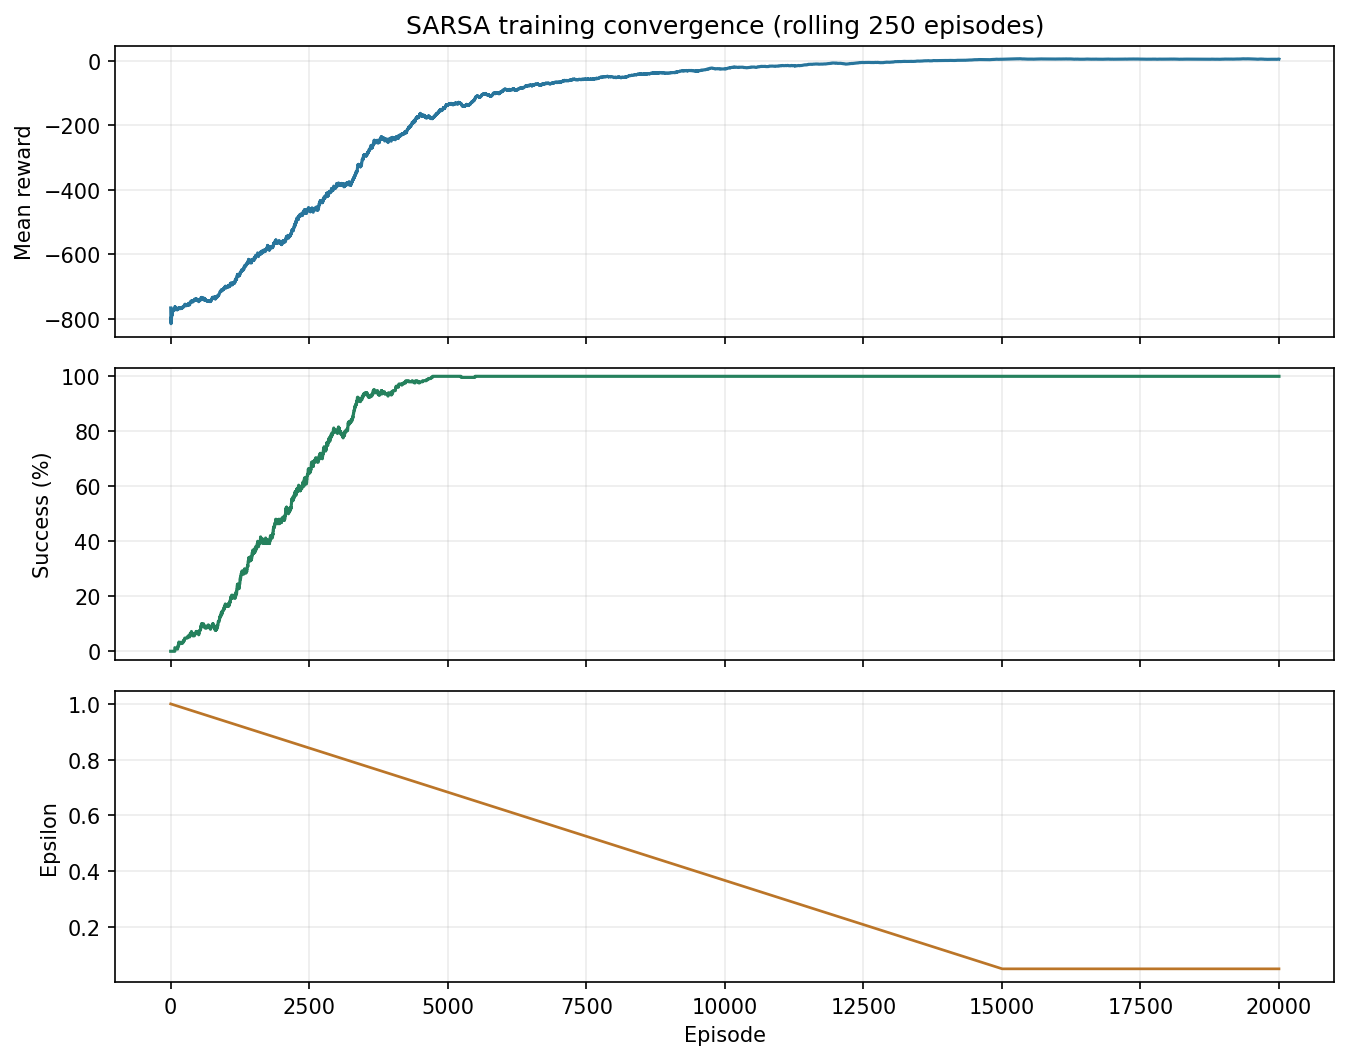


 evaluation_comparison.png


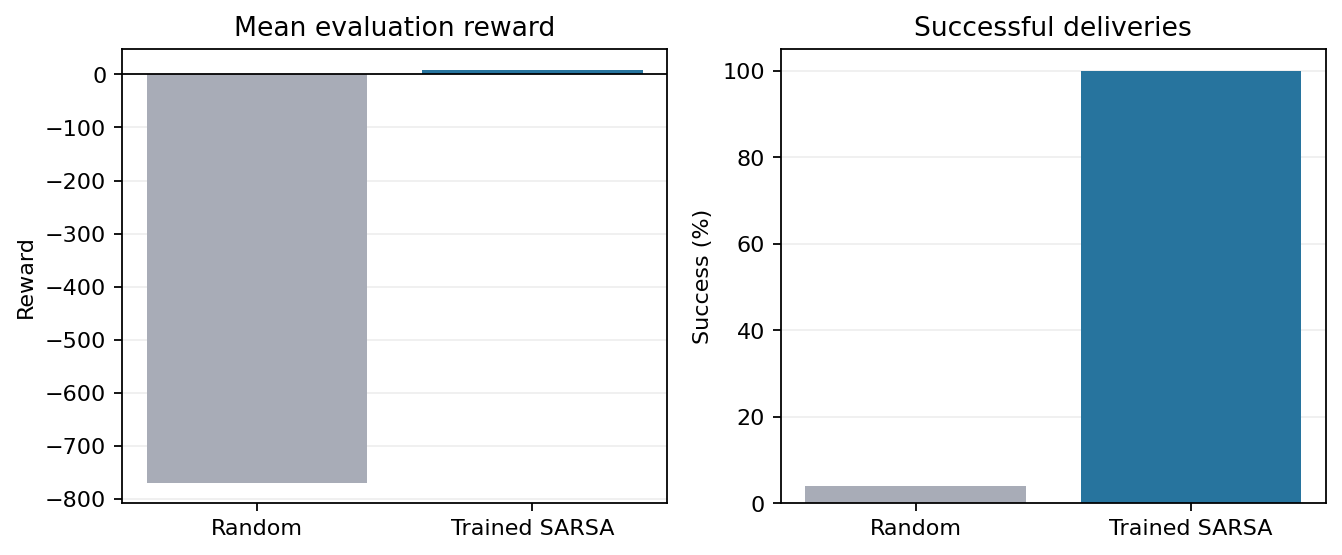


 hyperparameter_sensitivity.png


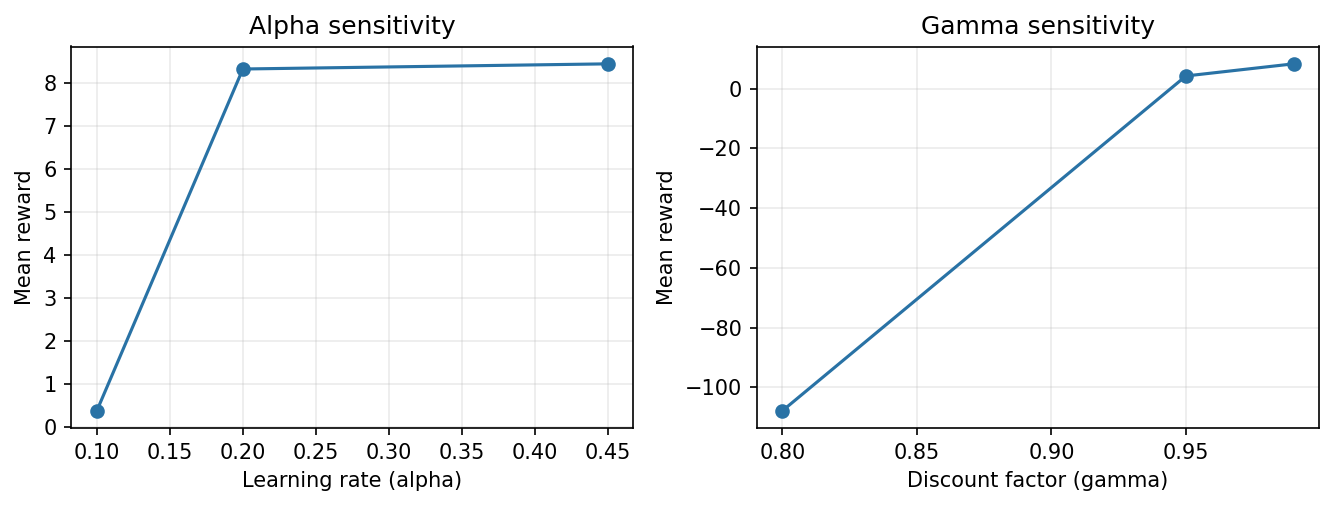

In [18]:
from IPython.display import display, Image as IPythonImage
from pathlib import Path
for f in ['training_convergence.png', 'evaluation_comparison.png','hyperparameter_sensitivity.png']:
    print('\n', f)
    display(IPythonImage(filename=str(Path('outputs')/f)))

### 12. Show the learned taxi in action

The GIF shows a **successful greedy trajectory** from the trained table, rendered frame-by-frame by Gymnasium. The next cell also reloads the saved model and prints the measured evaluation results.

Loaded Q table shape: (500, 6)
Backend: Gymnasium Taxi-v4 (official)
Trained SARSA: {'mean_reward': 8.62, 'success_rate': 1.0, 'mean_steps': 12.38, 'reward_std': 2.602998271224935, 'episodes': 100}
Random baseline: {'mean_reward': -769.19, 'success_rate': 0.04, 'mean_steps': 195.74, 'reward_std': 113.94680293891531, 'episodes': 100}
Successful rollout: {'seed': 60000, 'actions': [1, 1, 4, 0, 3, 0, 3, 3, 3, 1, 1, 5], 'total_reward': 9, 'steps': 12, 'success': True}


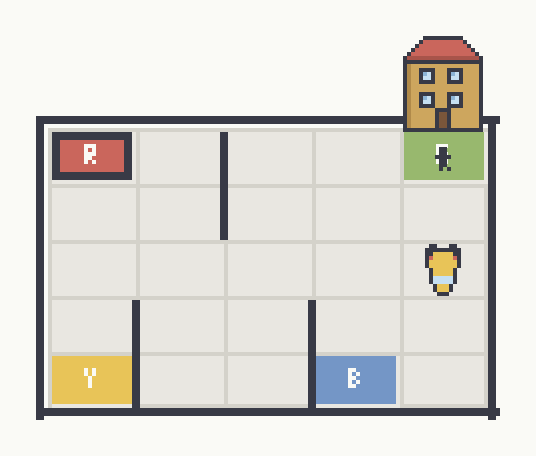

In [19]:
import json
import numpy as np
from IPython.display import display, Image as IPythonImage

Q = np.load('outputs/sarsa_q_table.npy')
info = json.loads(Path('outputs/results.json').read_text())
print('Loaded Q table shape:', Q.shape)
print('Backend:', info['meta']['backend_label'])
print('Trained SARSA:', info['evaluation']['trained'])
print('Random baseline:', info['evaluation']['random'])
print('Successful rollout:', info['rollout'])
display(IPythonImage(filename='outputs/trained_taxi.gif'))

### 13. Preview the technical report and download the entire ZIP

The technical report is **maximum three pages**. The submission ZIP includes all source files and generated artifacts. Keep this notebook (`File > Download > Download .ipynb`) alongside your GitHub repository; Colab sometimes stores the active notebook outside `/content`, so the notebook itself may need a separate download.

In [20]:
from IPython.display import display
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

zip_path = Path('/content/Syed_M_Awais_Raza_FA23_BAI_044_SARSA.zip')
with ZipFile(zip_path, 'w', compression=ZIP_DEFLATED) as z:
    for f in sorted(PROJECT.rglob('*')):
        if f.is_file() and '__pycache__' not in f.parts and '.ipynb_checkpoints' not in f.parts:
            z.write(f, arcname=str(Path(PROJECT.name) / f.relative_to(PROJECT)))
    # If the uploaded notebook is locally available, include it automatically.
    for possible in [Path('/content/Awais_SARSA_Taxi_Colab.ipynb'), Path('/content/'+PROJECT.name+'.ipynb')]:
        if possible.is_file():
            z.write(possible,arcname=str(Path(PROJECT.name)/'Awais_SARSA_Taxi_Colab.ipynb'))
            break
print('ZIP saved:', zip_path)
print('Report:', PROJECT/'outputs'/'technical_report.pdf')
files.download(str(zip_path))

ZIP saved: /content/Syed_M_Awais_Raza_FA23_BAI_044_SARSA.zip
Report: /content/Syed_M_Awais_Raza_SARSA_Assignment/outputs/technical_report.pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>